# Encontro 7 — Agentes e acoplamento

**Modelagem Dinâmica Espacial · PPGC&TAmb/UFMA**

Duas ideias neste encontro:

1. **Agentes.** Em vez de células que mudam de estado, indivíduos que **decidem e se movem** (pessoas, animais, produtores rurais). Vamos rodar e ler um modelo pronto, o de segregação de Schelling.
2. **Acoplamento.** Juntar modelos de paradigmas diferentes no mesmo relógio. Vamos ligar uma dinâmica de sistemas (quanto desmatar por ano) a um autômato celular (onde desmatar). Essa divisão "quanto × onde" é a estrutura dos modelos de mudança de uso da terra que começam no encontro 8.

Rode as células na ordem. 🔧 = troque um número e rode de novo; ✏️ = responda.

## 0. Preparação

In [1]:
# !pip install -q "dissmodel==0.6.6" "dissmodel-abm @ git+https://github.com/DisSModel/dissmodel-abm.git@v0.2.0"
import contextlib, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from dissmodel.core import Environment, Model
from dissmodel.geo.raster.backend import RasterBackend, DIRS_MOORE
from dissmodel_abm.models import Schelling


def rodar(passos, criar, anotar=None):
    """Cria os modelos com `criar()`, roda `passos` passos e devolve o que `anotar(objetos, passo)` leu."""
    env = Environment(start_time=1, end_time=passos)
    objetos = criar()
    linhas = []
    if anotar is not None:
        linhas.append({"passo": 0, **anotar(objetos, 0)})

        class Anotador(Model):          # criado por último: roda depois dos outros modelos
            def execute(self):
                t = int(self.env.now())
                linhas.append({"passo": t, **anotar(objetos, t)})
        Anotador()
    with contextlib.redirect_stdout(io.StringIO()):
        env.run()
    return objetos, pd.DataFrame(linhas).set_index("passo") if linhas else None

## 1. Agentes: o modelo de segregação de Schelling

Thomas Schelling (1971) perguntou: se as pessoas toleram ser minoria na vizinhança, mas preferem não ser minoria **demais**, a cidade fica segregada?

O modelo, na versão do TerraME (pacote `logo`), portada para o `dissmodel-abm`:

- grade 25 × 25 com 5% de células livres; cada agente é de um de dois grupos, sorteado;
- um agente fica **insatisfeito** se tiver menos de `preference` vizinhos do próprio grupo (de 8 possíveis);
- a cada passo, **um** agente insatisfeito, sorteado, muda para uma célula livre qualquer.

Diferente do autômato celular, aqui o que se move é o **agente**; a célula é só o lugar onde ele está.

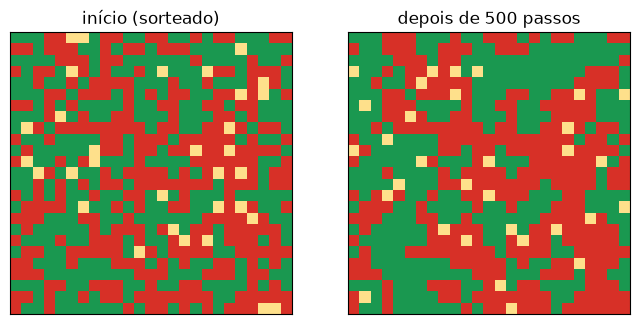

In [2]:
cores = ListedColormap(["#fee08b", "#1a9850", "#d73027"])   # livre, grupo 1, grupo 2

env = Environment(start_time=1, end_time=500)
modelo = Schelling(preference=3, seed=1)            # 3 vizinhos iguais (de 8) bastam
comeco = modelo.cs.backend.arrays["state"].copy()
with contextlib.redirect_stdout(io.StringIO()):
    env.run()
fim = modelo.cs.backend.arrays["state"].copy()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(8, 4))
a1.imshow(comeco, cmap=cores, vmin=0, vmax=2); a1.set_title("início (sorteado)")
a2.imshow(fim, cmap=cores, vmin=0, vmax=2); a2.set_title("depois de 500 passos")
for a in (a1, a2): a.set_xticks([]); a.set_yticks([])

Cada agente aceita até 5 vizinhos do outro grupo (precisa de só 3 iguais, entre 8). Mesmo assim, a cidade termina em manchas de um grupo só. Ninguém quis segregação; ela **emergiu** das decisões individuais.

Para medir, usamos a fração de vizinhos do mesmo grupo, em média, entre todos os agentes:

In [3]:
def vizinhos_iguais(estado):
    """Fração média de vizinhos (ocupados) do mesmo grupo, com borda periódica como no modelo."""
    iguais = np.zeros(estado.shape); ocupados = np.zeros(estado.shape)
    for dr, dc in DIRS_MOORE:
        viz = np.roll(estado, (dr, dc), axis=(0, 1))
        ocupados += viz > 0
        iguais += (viz == estado) & (viz > 0)
    agentes = estado > 0
    return float((iguais[agentes] / np.maximum(ocupados[agentes], 1)).mean())

print(f"vizinhos do mesmo grupo: início {vizinhos_iguais(comeco):.0%}   fim {vizinhos_iguais(fim):.0%}")

vizinhos do mesmo grupo: início 52%   fim 65%


🔧 **Preferência.** Rode com preferência de 1 a 5 vizinhos iguais (de 8).

,preferência (iguais em 8),vizinhos iguais no fim,insatisfeitos no fim
0,1,52%,0%
1,2,57%,1%
2,3,65%,6%
3,4,73%,11%
4,5,70%,27%


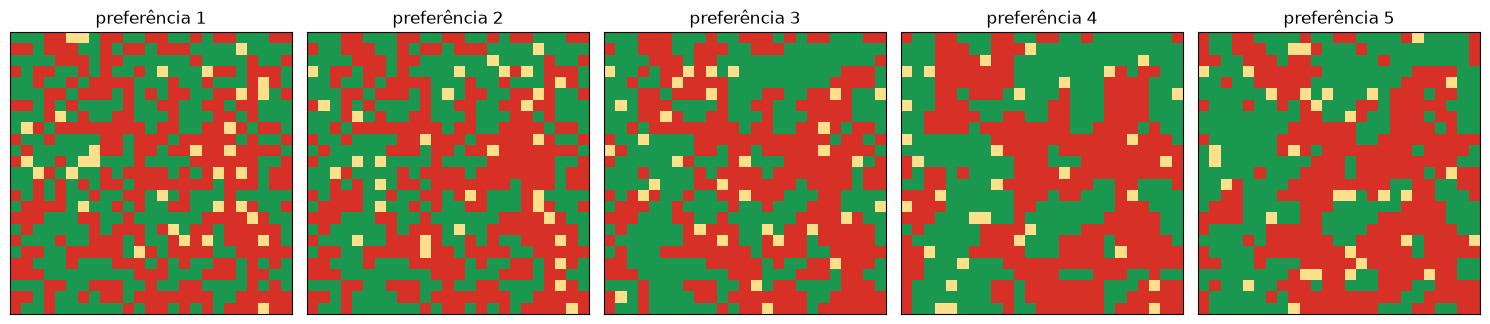

In [4]:
tabela = []
fig, eixos = plt.subplots(1, 5, figsize=(15, 3.2))
for ax, pref in zip(eixos, [1, 2, 3, 4, 5]):
    m, _ = rodar(500, criar=lambda: Schelling(preference=pref, seed=1))
    estado = m.cs.backend.arrays["state"]
    tabela.append({"preferência (iguais em 8)": pref,
                   "vizinhos iguais no fim": f"{vizinhos_iguais(estado):.0%}",
                   "insatisfeitos no fim": f"{m.percent_unhappy():.0f}%"})
    ax.imshow(estado, cmap=cores, vmin=0, vmax=2); ax.set_title(f"preferência {pref}")
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
pd.DataFrame(tabela)

✏️ **Pergunta 1.** Com preferência 5 (exige maioria de iguais) a cidade termina **menos** segregada que com 4, e um quarto dos agentes continua insatisfeito. Por que um modelo em que todos são mais exigentes pode terminar menos segregado? (Dica: há só 5% de lugares livres e um agente se move por passo.)

## 2. Comparar um modelo com sorteio: 50 rodadas contra 50 do TerraME

No encontro 6, o Jogo da Vida bateu com o TerraME célula a célula. Aqui isso é impossível: o TerraME e o Python sorteiam números diferentes. O que se compara é a **distribuição**: 50 rodadas de cada lado, com sementes diferentes.

O `terrame-goldens` guarda, para 50 sementes, a porcentagem de agentes no grupo de insatisfeitos a cada passo. O `dissmodel-abm` guarda o mesmo número em `modelo.unhappy`.

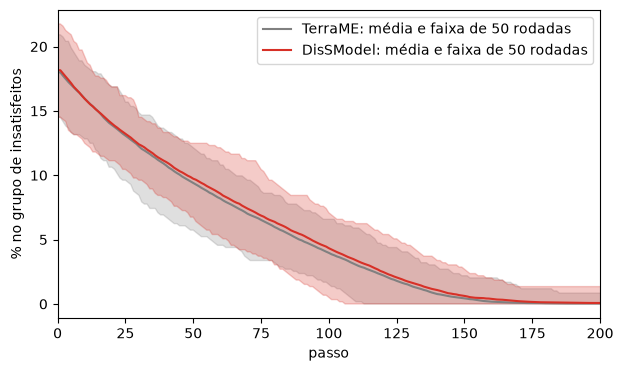

In [5]:
URL = "https://raw.githubusercontent.com/LambdaGeo/terrame-goldens/v0.1.0/goldens/logo/schelling.csv.gz"
ref = pd.read_csv(URL)
terrame = ref[ref.variable == "unhappy"].pivot(index="step", columns="seed", values="value")

nosso = pd.concat({s: rodar(500, criar=lambda: Schelling(seed=s),
                            anotar=lambda m, t: {"u": m.unhappy})[1]["u"]
                   for s in range(1, 51)}, axis=1)

fig, ax = plt.subplots(figsize=(7, 4))
for nome, tab, cor in [("TerraME", terrame, "gray"), ("DisSModel", nosso, "#d73027")]:
    ax.fill_between(tab.index, tab.min(axis=1), tab.max(axis=1), color=cor, alpha=0.25)
    ax.plot(tab.index, tab.mean(axis=1), color=cor, label=f"{nome}: média e faixa de 50 rodadas")
ax.set(xlabel="passo", ylabel="% no grupo de insatisfeitos", xlim=(0, 200)); ax.legend();

In [6]:
for passo in (0, 25, 50, 100):
    print(f"passo {passo:3d}  média TerraME {terrame.loc[passo].mean():5.1f}%   média DisSModel {nosso.loc[passo].mean():5.1f}%")

passo   0  média TerraME  18.0%   média DisSModel  18.2%
passo  25  média TerraME  13.1%   média DisSModel  13.2%
passo  50  média TerraME   9.4%   média DisSModel   9.7%
passo 100  média TerraME   4.0%   média DisSModel   4.3%


As duas faixas se sobrepõem: o comportamento é o mesmo, embora nenhuma rodada seja igual a outra.

Um detalhe que a comparação revela: o grupo de insatisfeitos chega a **zero**, mas no fim ainda há cerca de 6% de agentes insatisfeitos (a tabela da Parte 1). No original do TerraME, o grupo é montado uma vez e só **remove** quem ficou satisfeito; quem fica insatisfeito depois de uma mudança nunca volta a ser verificado. O porte reproduz esse comportamento de propósito, e o documenta.

✏️ **Pergunta 2.** Corrigir esse comportamento deixaria o modelo "melhor", mas diferente do original. Num trabalho científico, como você decidiria? O que precisaria escrever no método?

## 3. Acoplamento: quanto (dinâmica de sistemas) e onde (autômato celular)

Agora juntamos dois paradigmas no mesmo relógio:

- **Demanda** (dinâmica de sistemas, como no encontro 5): a cada ano, uma fração da floresta remanescente é desmatada. Ela responde **quanto**.
- **Alocação** (autômato celular, como no encontro 6): escolhe **onde**, preferindo células de floresta com vizinhos já desmatados.

Os dois são `Model` do DisSModel no mesmo `Environment`. A demanda é criada primeiro, então roda primeiro em cada ano; a alocação lê o valor que ela acabou de calcular.

In [7]:
FLORESTA, DESMATADO = 0, 1

class Demanda(Model):
    """Dinâmica de sistemas: quantas células desmatar neste ano."""
    def setup(self, floresta, taxa):
        self.floresta = floresta          # estoque (células)
        self.taxa = taxa                  # fração desmatada por ano
        self.neste_ano = 0

    def execute(self):
        self.neste_ano = round(self.taxa * self.floresta)
        self.floresta -= self.neste_ano


class Alocacao(Model):
    """Autômato celular: onde desmatar, perto do que já foi desmatado."""
    def setup(self, backend, demanda, peso_vizinhos, semente):
        self.b, self.demanda, self.peso = backend, demanda, peso_vizinhos
        self.rng = np.random.default_rng(semente)

    def execute(self):
        uso = self.b.arrays["uso"]
        vizinhos = self.b.focal_sum_mask(uso == DESMATADO, DIRS_MOORE)            # 0 a 8
        potencial = self.peso * vizinhos / 8 + self.rng.random(uso.shape)          # contágio + acaso
        potencial[uso != FLORESTA] = -np.inf                                       # só floresta pode mudar
        escolhidas = np.argsort(potencial, axis=None)[::-1][: self.demanda.neste_ano]
        uso.flat[escolhidas] = DESMATADO

O território: 100 × 100 células de floresta, com uma estrada no meio já desmatada.

,floresta (demanda),floresta (mapa)
passo,,
0,9900,9900
10,8090,8090
20,6611,6611
30,5402,5402


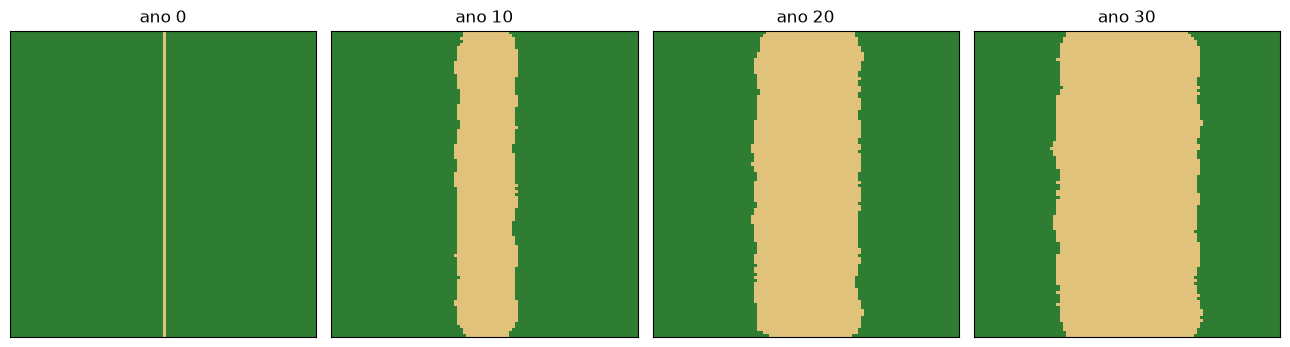

In [8]:
def paisagem(n=100):
    uso = np.full((n, n), FLORESTA, dtype=np.int8)
    uso[:, n // 2] = DESMATADO                      # a estrada
    b = RasterBackend(shape=(n, n)); b.set("uso", uso)
    return b

def simular(taxa=0.02, peso_vizinhos=5.0, anos=30, semente=1):
    b = paisagem()
    def criar():
        d = Demanda(floresta=int((b.arrays["uso"] == FLORESTA).sum()), taxa=taxa)   # 1º: quanto
        a = Alocacao(backend=b, demanda=d, peso_vizinhos=peso_vizinhos, semente=semente)  # 2º: onde
        return d, a
    fotos = {}
    def anotar(obj, t):
        d, _ = obj
        if t in (0, 10, 20, 30): fotos[t] = b.arrays["uso"].copy()
        return {"floresta (demanda)": d.floresta,
                "floresta (mapa)": int((b.arrays["uso"] == FLORESTA).sum())}
    _, serie = rodar(anos, criar, anotar)
    return serie, fotos

serie, fotos = simular()
fig, eixos = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, (t, f) in zip(eixos, sorted(fotos.items())):
    ax.imshow(f, cmap=ListedColormap(["#2e7d32", "#e0c27a"]), vmin=0, vmax=1)
    ax.set_title(f"ano {t}"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
serie.iloc[[0, 10, 20, 30]]

As duas colunas da tabela batem a cada ano: o autômato aloca exatamente o que a demanda pede. Se não batessem, os dois modelos estariam contando coisas diferentes.

🔧 **Separar quanto de onde.** Rode as quatro combinações abaixo e compare.

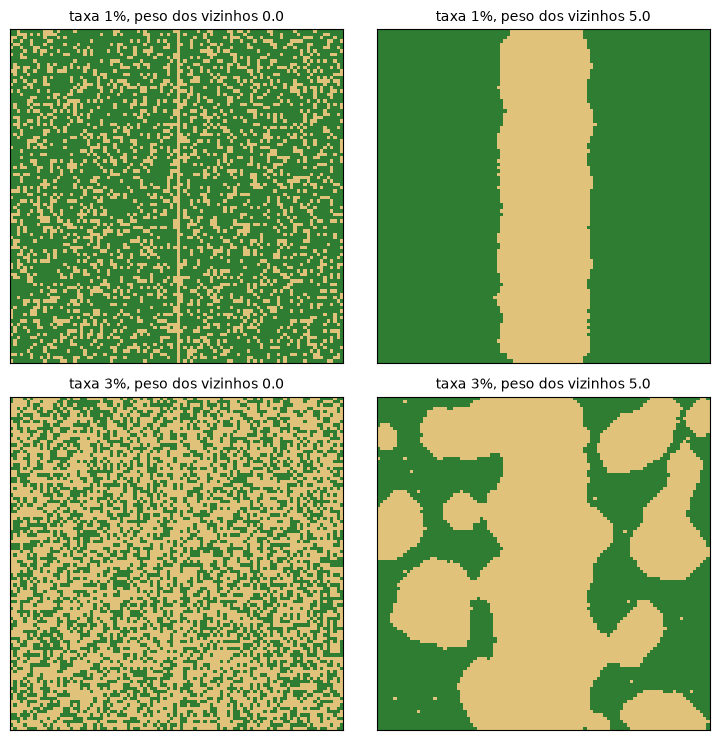

In [9]:
fig, eixos = plt.subplots(2, 2, figsize=(7.5, 7.5))
for ax, (taxa, peso) in zip(eixos.flat, [(0.01, 0.0), (0.01, 5.0), (0.03, 0.0), (0.03, 5.0)]):
    _, f = simular(taxa=taxa, peso_vizinhos=peso)
    ax.imshow(f[30], cmap=ListedColormap(["#2e7d32", "#e0c27a"]), vmin=0, vmax=1)
    ax.set_title(f"taxa {taxa:.0%}, peso dos vizinhos {peso}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()

✏️ **Pergunta 3.** A taxa mudou o quê no mapa? E o peso dos vizinhos? Um modelo LUCC precisa das duas coisas certas; qual delas você conseguiria checar só com a área desmatada por ano, e qual precisaria de mapas?

## 4. O projeto final

Até o próximo encontro, cada aluno escreve uma página com:

1. **Pergunta.** O que o modelo deve responder?
2. **Área e período.** Onde, quando, e com que tamanho de célula?
3. **Paradigma.** Dinâmica de sistemas, autômato celular, agentes ou acoplamento? Por quê?
4. **Estado e regra.** O que cada célula (ou agente) guarda e como muda?
5. **Dados.** Que mapas e séries você precisa (MapBiomas, PRODES, censo...)?
6. **Como saber se deu certo.** Que resultado observado você compararia com o simulado?

## Para casa

1. No Schelling, troque a fração de células livres para 0,20 (`Schelling(preference=3, free_space=0.2, seed=1)`). A segregação final aumenta ou diminui?
2. No acoplamento, faça a taxa de desmatamento cair à metade a partir do ano 15 (uma política). Dica: em `Demanda.execute`, use `self.env.now()` para saber o ano.
3. Esboço do projeto (seção 4).